# Minor (high-tide) flooding

**Indicator:** number of days and hours per storm year with hourly sea level more than {glue:text}`threshold` cm above Mean Higher High Water (MHHW) at the tide gauge, their trends and their relationship with ENSO.

```{glue:figure} fig-threshold_counts_enso
:scale: 50%
:align: right
```

Minor flooding (also called high-tide, king-tide or nuisance flooding) occurs when exceptionally high tides combine with waves, storm surges or seasonal and ENSO-related sea-level anomalies. As mean sea level rises, the same tides exceed flood thresholds more often. A **minor flood day** is a day on which the hourly sea level exceeds the threshold at least once; a **flood hour** is an hourly value above the threshold.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

In [2]:
from pathlib import Path
import sys, warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from myst_nb import glue

warnings.filterwarnings('ignore', category=RuntimeWarning)

root_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
repo_root = next((p for p in root_candidates if (p / 'functions' / 'sea_level.py').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Could not locate the CIndRA repository root (functions/sea_level.py).')
sys.path.insert(0, str(repo_root / 'functions'))
import datetime

from data_downloaders import download_oni_index, download_uhslc_data
from sea_level import (
    COMPLETENESS_THRESHOLD, ONI_URL, build_output_filename, build_site_tag, detect_enso_events,
    enso_by_storm_year, flood_counts_per_storm_year, get_trend_info, get_uhslc_datum,
    load_site_config, monthly_flood_day_matrix, resolve_eez, save_dict_json, save_table_to_csv,
    sea_level_config_path, station_series,
)
from sea_level_plotting import (
    plot_flood_counts_with_oni, plot_flood_counts_with_trend, plot_flood_matrix_summary,
    plot_histogram_with_threshold, plot_simple_timeseries,
)

## 1. Configuration

In [3]:
site_key = 'Palau'  # sea-level configuration written by 00_sea_level_setup.ipynb
site_cfg = load_site_config(sea_level_config_path(repo_root, site_key))

country = site_cfg['country']
uhslc_id = int(site_cfg['selected_uhslc_id'])
station = site_cfg['station']
station_lon, station_lat = float(site_cfg['station_lon']), float(site_cfg['station_lat'])
start_date = pd.Timestamp(site_cfg['start_date'])
end_date = pd.Timestamp(site_cfg['end_date'])
sea_level_dir = repo_root / site_cfg['sea_level_data_dir']
eez, eez_geometry = resolve_eez(country, repo_root / site_cfg['eez_file'])

site_name = site_cfg['site_name']
site_tag = build_site_tag(site_name, station_lon, station_lat)
fig_dir = repo_root / 'outputs' / 'figures' / site_tag
tab_dir = repo_root / 'outputs' / 'tables' / site_tag
matrix_dir = repo_root / 'matrix_cc' / 'figures'
for directory in (fig_dir, tab_dir, matrix_dir):
    directory.mkdir(parents=True, exist_ok=True)

def out(name, ext='png'):
    return build_output_filename(name, site_name, station_lon, station_lat, ext=ext)

glue('station', station, display=False)
glue('country', country, display=False)
print(f'{station}, {country} (UHSLC {uhslc_id:03d}); analysis period {start_date:%Y-%m-%d} to {end_date:%Y-%m-%d}')
print(f'Outputs: {fig_dir.relative_to(repo_root)} and {tab_dir.relative_to(repo_root)}')
threshold = float(site_cfg.get('flood_threshold_cm', 30))  # cm above MHHW
glue('threshold', threshold, display=False)

Malakal, Palau (UHSLC 007); analysis period 1993-01-01 to 2024-12-31
Outputs: outputs/figures/palau_uhslc007_lat7p329_lon134p450 and outputs/tables/palau_uhslc007_lat7p329_lon134p450


## 2. Hourly sea level relative to MHHW

UHSLC hourly sea level is given in mm relative to the station datum. The MHHW value and the tidal datum epoch are read from the UHSLC datum table for the station.

In [4]:
rsl = download_uhslc_data(sea_level_dir, uhslc_id, 'hourly')
mhhw, datum_table = get_uhslc_datum(uhslc_id, 'MHHW')
hourly_mhhw = station_series(rsl) - mhhw  # mm above MHHW

epoch = datum_table.loc[datum_table['Name'] == 'Epoch', 'Value'].values[0]
epoch_start = datetime.datetime.strptime(epoch.split(' ')[0], '%d-%b-%Y')
epoch_end = datetime.datetime.strptime(epoch.split(' ')[2], '%d-%b-%Y')
print(f'MHHW = {mhhw:.0f} mm above station datum (tidal epoch {epoch_start:%Y}–{epoch_end:%Y}).')
datum_table[datum_table['Name'].isin(['Epoch', 'MHHW', 'MHW', 'MSL', 'MLLW', 'GT'])]

MHHW = 2160 mm above station datum (tidal epoch 1983–2001).


,Name,Value,Description
1,Epoch,01-Jan-1983 to 31-Dec-2001,Tidal Datum Analysis Period
2,MHHW,2160,Mean Higher-High Water (mm)
3,MHW,2088,Mean High Water (mm)
5,MSL,1532,Mean Sea Level (mm)
8,MLLW,754,Mean Lower-Low Water (mm)
10,GT,1406,Great Diurnal Range (mm)


The analysis starts with the storm year before the tidal epoch and ends with the last complete storm year (May–April).

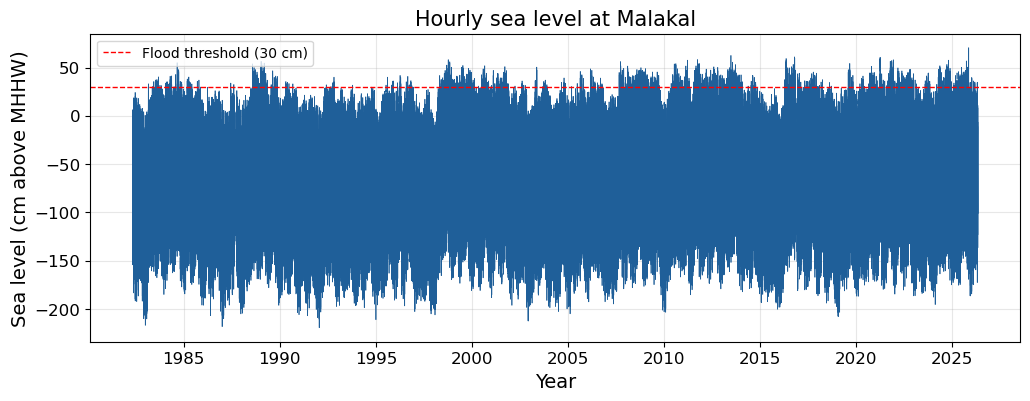

In [5]:
last = pd.Timestamp(hourly_mhhw.time.values[-1])
first_storm_year = max(epoch_start.year - 1, pd.Timestamp(hourly_mhhw.time.values[0]).year)
last_storm_year = last.year - 1 if last >= pd.Timestamp(f'{last.year}-04-30 23:00') else last.year - 2
hourly_data = hourly_mhhw.sel(time=slice(f'{first_storm_year}-05-01', f'{last_storm_year + 1}-04-30 23:59'))
glue('startDataDateTime', f'{first_storm_year}-05-01', display=False)
glue('endDataDateTime', f'{last_storm_year + 1}-04-30', display=False)

fig, ax = plot_simple_timeseries(hourly_data.time.values, hourly_data.values / 10, 'Sea level (cm above MHHW)',
                                 title=f'Hourly sea level at {station}')
ax.axhline(threshold, color='r', ls='--', lw=1, label=f'Flood threshold ({threshold:g} cm)')
ax.legend(loc='upper left', fontsize=10)
plt.show()

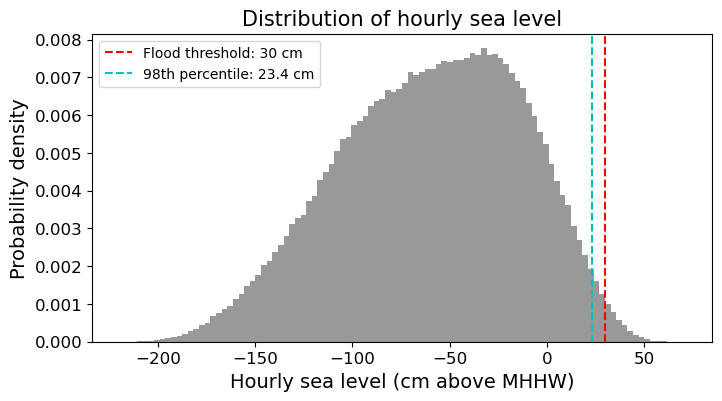

1.01% of valid hours exceed the threshold; the 98th percentile is 23.4 cm above MHHW.


In [6]:
fig, ax, threshold98 = plot_histogram_with_threshold(hourly_data, threshold)
plt.show()
print(f'{100 * float((hourly_data > threshold * 10).sum() / hourly_data.count()):.2f}% of valid hours exceed the threshold; '
      f'the 98th percentile is {threshold98:.1f} cm above MHHW.')

## 3. Flood days and hours per storm year

Storm years with less than 75% hourly coverage are excluded (shown as ✕ in the charts) so that missing data are not counted as flood-free.

In [7]:
flood_table = flood_counts_per_storm_year(hourly_data, threshold, COMPLETENESS_THRESHOLD)
oni = download_oni_index(ONI_URL)
enso_events = detect_enso_events(oni)
flood_table = flood_table.merge(enso_by_storm_year(enso_events), left_on='year_storm', right_index=True, how='left')
print(f"{int(flood_table['flood_days_count'].notna().sum())} complete storm years; "
      f"{int(flood_table['flood_days_count'].isna().sum())} excluded for completeness.")
flood_table.tail(10)

44 complete storm years; 0 excluded for completeness.


,year_storm,completeness,flood_days_raw,flood_hours_raw,flood_days_count,flood_hours_count,ONI Mode,ONI
34,2016,0.914384,81,204,81,204,El Nino,-0.089167
35,2017,0.999201,63,115,63,115,La Nina,-0.298333
36,2018,0.993836,3,3,3,3,El Nino,0.634167
37,2019,0.988730,28,65,28,65,El Nino,0.536667
38,2020,1.000000,60,151,60,151,La Nina,-0.661667
39,2021,0.999201,76,185,76,185,La Nina,-0.645000
40,2022,0.998973,69,148,69,148,La Nina,-0.593333
41,2023,0.985542,27,58,27,58,El Nino,1.324167
42,2024,0.992580,76,185,76,185,Neutral,-0.095000
43,2025,0.998516,89,203,89,203,Neutral,-0.222500


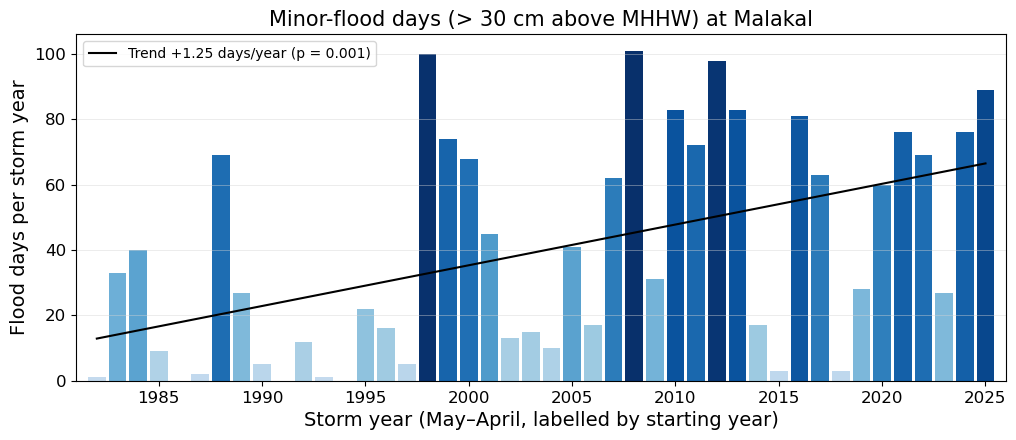

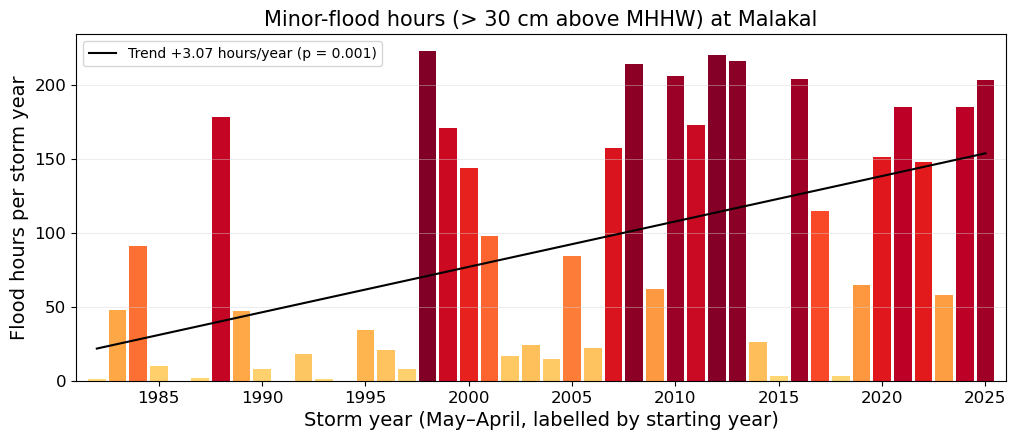

In [8]:
fig, ax, slope_days, p_value_days, trend_days = plot_flood_counts_with_trend(flood_table, 'days', 'Blues', station, threshold)
glue('days_per_year_trend', float(slope_days), display=False)
glue('p_value_days', float(p_value_days), display=False)
plt.show()

fig, ax, slope_hours, p_value_hours, trend_hours = plot_flood_counts_with_trend(flood_table, 'hours', 'YlOrRd', station, threshold)
glue('hours_per_year_trend', float(slope_hours), display=False)
glue('p_value_hours', float(p_value_hours), display=False)
fig.savefig(fig_dir / out('SL_FloodFrequency_threshold_counts_hours'), dpi=300, bbox_inches='tight')
plt.show()

## 4. Flood days and ENSO

Each storm year is coloured by its dominant ENSO phase.

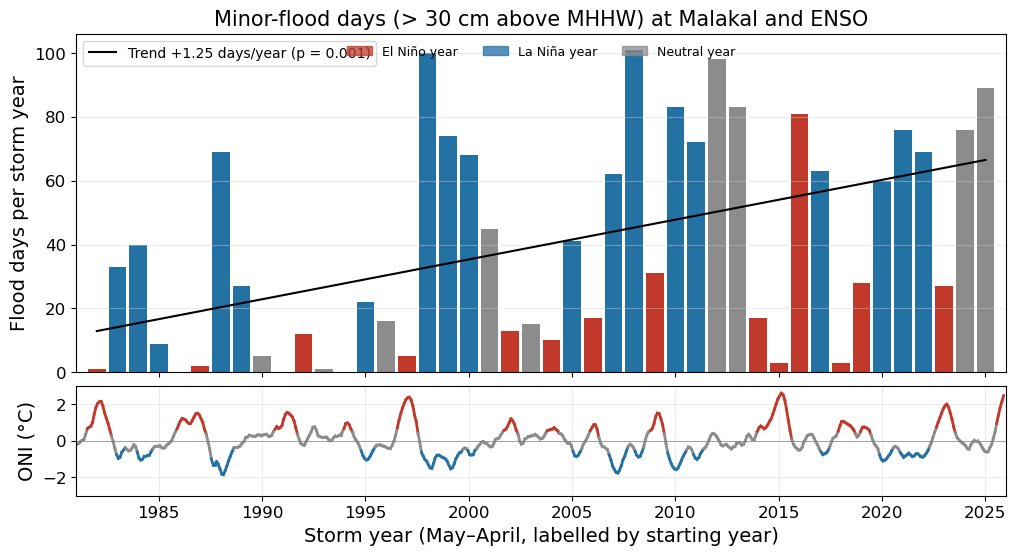

In [9]:
fig, axes, _, _ = plot_flood_counts_with_oni(flood_table, enso_events, station, threshold)
glue('fig-threshold_counts_enso', fig, display=False)
fig.savefig(fig_dir / out('SL_FloodFrequency_threshold_counts_days'), dpi=300, bbox_inches='tight')

```{glue:figure} fig-threshold_counts_enso
:name: "fig-threshold_counts_enso"

Minor-flood days per storm year at the {glue:text}`station` tide gauge ({glue:text}`startDataDateTime` to {glue:text}`endDataDateTime`), coloured by dominant ENSO phase, with the ONI below. The linear trend is {glue:text}`days_per_year_trend:.2f` days per year (p = {glue:text}`p_value_days:.3f`).
```

## 5. Summary statistics

In [10]:
valid = flood_table.dropna(subset=['flood_days_count'])
valid_years = valid['year_storm'].to_numpy()
decade_edges = list(range(int(valid_years.min()) // 10 * 10, int(valid_years.max()) + 10, 10))
decadal = (valid.assign(decade=pd.cut(valid['year_storm'], decade_edges, right=False,
                                      labels=[f'{d}–{d + 9}' for d in decade_edges[:-1]]))
           .groupby('decade', observed=True)
           .agg(storm_years=('year_storm', 'size'), mean_flood_days=('flood_days_count', 'mean'),
                mean_flood_hours=('flood_hours_count', 'mean'))
           .round(1))

summary_stats = pd.DataFrame([
    ('Complete storm years', int(len(valid))),
    ('Total flood days', int(valid['flood_days_count'].sum())),
    ('Mean flood days per year', round(float(valid['flood_days_count'].mean()), 1)),
    ('Maximum flood days in a storm year', int(valid['flood_days_count'].max())),
    ('Storm year of maximum flood days', int(valid.loc[valid['flood_days_count'].idxmax(), 'year_storm'])),
    ('Total flood hours', int(valid['flood_hours_count'].sum())),
    ('Mean flood hours per year', round(float(valid['flood_hours_count'].mean()), 1)),
    ('Trend in flood days (days/yr)', round(float(slope_days), 2)),
    ('p-value, flood-day trend', round(float(p_value_days), 3)),
    ('Trend in flood hours (hours/yr)', round(float(slope_hours), 2)),
    ('p-value, flood-hour trend', round(float(p_value_hours), 3)),
], columns=['Statistic', 'Value'])
display(summary_stats)
decadal

,Statistic,Value
0,Complete storm years,44.000
1,Total flood days,1747.000
2,Mean flood days per year,39.700
3,Maximum flood days in a storm year,101.000
4,Storm year of maximum flood days,2008.000
5,Total flood hours,3859.000
6,Mean flood hours per year,87.700
7,Trend in flood days (days/yr),1.250
8,"p-value, flood-day trend",0.001
9,Trend in flood hours (hours/yr),3.070


,storm_years,mean_flood_days,mean_flood_hours
decade,,,
1980–1989,8,22.6,47.1
1990–1999,10,23.5,48.4
2000–2009,10,40.3,83.7
2010–2019,10,53.1,123.1
2020–2029,6,66.2,155.0


## 6. Monthly distribution of flood days

The matrix shows flood days in each month of every complete storm year; the right-hand bars give each month's share of all flood days.

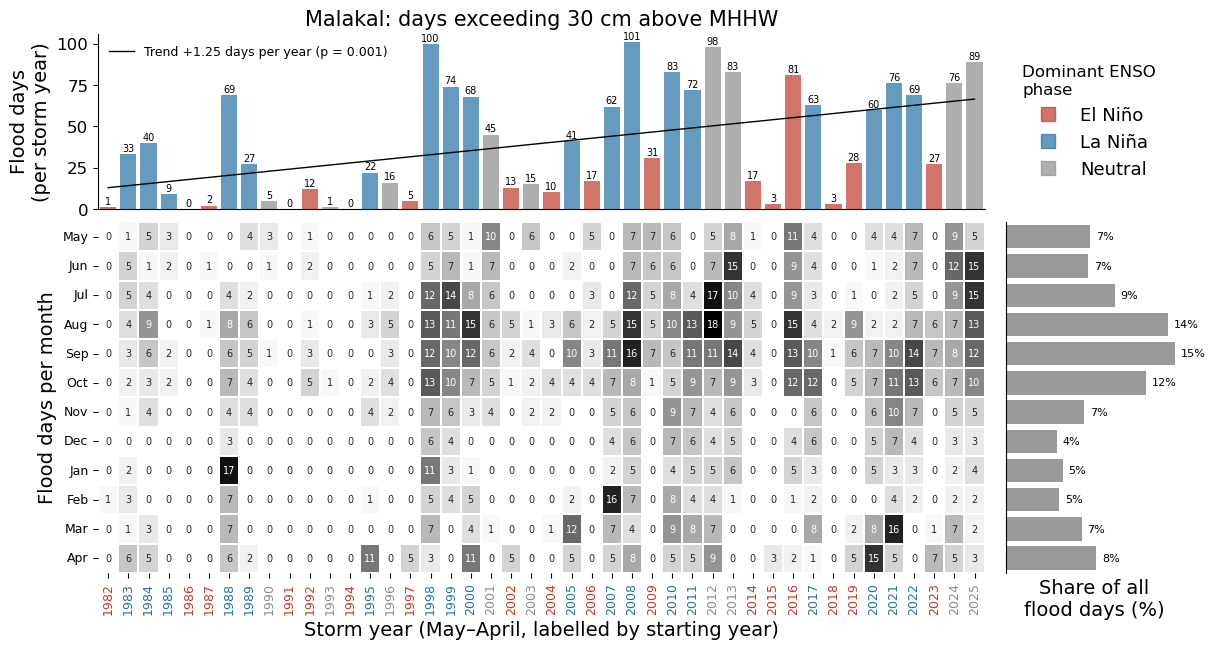

In [11]:
matrix, month_names = monthly_flood_day_matrix(hourly_data, threshold, valid_years)
fig, axs, _, _ = plot_flood_matrix_summary(matrix, flood_table, station, threshold)
fig.savefig(fig_dir / out('SL_FloodFrequency_threshold_counts_heatmap'), dpi=300, bbox_inches='tight')
fig.savefig(matrix_dir / out('F11_Minor_flood_matrix'), dpi=300, bbox_inches='tight')
plt.show()

## 7. Saved outputs

In [12]:
save_table_to_csv(flood_table, tab_dir, out('SL_flood_days_per_year', 'csv'))
save_table_to_csv(matrix.round(1).reset_index(), tab_dir, out('SL_flood_days_monthly_matrix', 'csv'))
save_table_to_csv(decadal.reset_index(), tab_dir, out('SL_flood_days_decadal', 'csv'))
ff_metrics = {
    'station': station,
    'uhslc_id': uhslc_id,
    'threshold_cm_above_mhhw': threshold,
    'mhhw_mm_station_datum': mhhw,
    'first_storm_year': int(first_storm_year),
    'last_storm_year': int(last_storm_year),
    'complete_storm_years': int(len(valid)),
    'mean_flood_days_per_year': float(valid['flood_days_count'].mean()),
    'mean_flood_hours_per_year': float(valid['flood_hours_count'].mean()),
    'flood_days_trend_per_year': float(slope_days),
    'flood_days_trend_p': float(p_value_days),
    'flood_hours_trend_per_year': float(slope_hours),
    'flood_hours_trend_p': float(p_value_hours),
}
save_dict_json(ff_metrics, tab_dir, out('SL_flood_frequency_summary_metrics', 'json'))
pd.Series(ff_metrics).to_frame('value')

,value
station,Malakal
uhslc_id,7
threshold_cm_above_mhhw,30.0
mhhw_mm_station_datum,2160.0
first_storm_year,1982
last_storm_year,2025
complete_storm_years,44
mean_flood_days_per_year,39.704545
mean_flood_hours_per_year,87.704545
flood_days_trend_per_year,1.246723


## Interpretation and reproducibility notes

- The threshold (30 cm above MHHW by default) is a common proxy for minor coastal flooding in the Pacific but does not account for local topography, waves or drainage; impacts can start at lower or higher levels.
- MHHW is taken from the UHSLC datum table for the station's tidal epoch; using another epoch shifts the counts.
- Counts use hourly Fast Delivery data, which can underestimate short-lived peaks.
- Incomplete storm years (< 75% of hours) are excluded from statistics and trends instead of being counted as zero.
- Trends in counts are descriptive linear fits; counts are bounded at zero and strongly modulated by ENSO and the 18.6-year nodal tidal cycle.